# Лабораторная работа 2. Рекомендательные системы


## Подготовка

In [2]:
%matplotlib inline

import json
import re
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

RAW = Path("data/raw")
INTERIM = Path("data/interim")
INTERIM.mkdir(parents=True, exist_ok=True)

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seqblue", ["#cde2fb", "#2a78d6", "#0d366b"])
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
    "figure.dpi": 110,
})

MODELS = ["MostPop", "ItemKNN", "EASE"]
MODEL_COLOR = dict(zip(MODELS, [CAT[3], CAT[0], CAT[2]]))
TOP_N = 20
K_MAIN = 10

## 1. Датасет и постановка задачи

> Выбрать датасет, подходящий для моделирования рекомендательной системы.  Хорошие источники данных: https://ods.ai/competitions/ (тут не все соревнования подходят, берите только то, что связано с рекомендательными системами, например https://ods.ai/competitions/vkrecsyschallengelsvd) и https://www.recsyschallenge.com/2026/ (тут можно подставлять любой год, начиная с 2016). Запрещено брать данные с Kaggle, так как по ним часто уже есть готовый EDA и baseline, а также датасет Movielens (любого размера).

> Сделать разведочный анализ данных (EDA), то есть описать исходные данные, а также посчитать статистические показатели, построить визуализации и дать им интерпретацию, подготовить отчёт по качеству данных (пропуски, дубли, выбросы). Четко выделить целевую переменную - “что именно рекомендуем?” При необходимости предобработать данные. Сделать выводы.

Используем [Amazon Reviews 2023](https://amazon-reviews-2023.github.io/), категорию Video Games: отзывы и карточки товаров. Источник — McAuley Lab. Категория содержит игры, консоли и аксессуары.

В отзывах используем `user_id`, `parent_asin`, `timestamp`, `rating`, `verified_purchase`; в карточках — название, бренд, цену и категории. `parent_asin` объединяет варианты товара.

Целевая переменная — факт будущего отзыва о ранее не встречавшемся пользователю товаре, независимо от оценки.


## 2. Загрузка данных

> Выбрать датасет, подходящий для моделирования рекомендательной системы.  Хорошие источники данных: https://ods.ai/competitions/ (тут не все соревнования подходят, берите только то, что связано с рекомендательными системами, например https://ods.ai/competitions/vkrecsyschallengelsvd) и https://www.recsyschallenge.com/2026/ (тут можно подставлять любой год, начиная с 2016). Запрещено брать данные с Kaggle, так как по ним часто уже есть готовый EDA и baseline, а также датасет Movielens (любого размера).



In [3]:
t0 = time.time()
reviews_path = INTERIM / "reviews.pkl"
if reviews_path.exists():
    reviews = pd.read_pickle(reviews_path)
else:
    cols = ["rating", "parent_asin", "user_id", "timestamp", "verified_purchase", "helpful_vote"]
    parts = []
    for ch in pd.read_json(RAW / "Video_Games.jsonl", lines=True, chunksize=300_000):
        parts.append(ch[cols])
    reviews = pd.concat(parts, ignore_index=True)
    reviews.to_pickle(reviews_path)
print(f"отзывы: {len(reviews):,} строк, загрузка {time.time()-t0:.0f} с")
reviews.head(3)

отзывы: 4,624,615 строк, загрузка 0 с


,rating,parent_asin,user_id,timestamp,verified_purchase,helpful_vote
0,4,B07DK1H3H5,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,2020-12-17 06:33:24.795,True,0
1,5,B07SRWRH5D,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,2020-04-16 15:31:54.941,False,1
2,5,B07MFMFW34,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,2017-03-30 12:37:11.000,True,0


### 2.1. Загрузка метаданных

> Выбрать датасет, подходящий для моделирования рекомендательной системы.  Хорошие источники данных: https://ods.ai/competitions/ (тут не все соревнования подходят, берите только то, что связано с рекомендательными системами, например https://ods.ai/competitions/vkrecsyschallengelsvd) и https://www.recsyschallenge.com/2026/ (тут можно подставлять любой год, начиная с 2016). Запрещено брать данные с Kaggle, так как по ним часто уже есть готовый EDA и baseline, а также датасет Movielens (любого размера).


In [4]:
t0 = time.time()
meta_path = INTERIM / "meta.pkl"
if meta_path.exists():
    meta = pd.read_pickle(meta_path)
else:
    cols = ["parent_asin", "title", "store", "price", "categories", "average_rating", "rating_number"]
    parts = []
    for ch in pd.read_json(RAW / "meta_Video_Games.jsonl", lines=True, chunksize=100_000):
        parts.append(ch[cols])
    meta = pd.concat(parts, ignore_index=True)
    meta.to_pickle(meta_path)
print(f"метаданные: {len(meta):,} товаров, загрузка {time.time()-t0:.0f} с")
meta.head(3)

метаданные: 137,269 товаров, загрузка 0 с


,parent_asin,title,store,price,categories,average_rating,rating_number
0,B000FH0MHO,Dash 8-300 Professional Add-On,Aerosoft,None,"[Video Games, PC, Games]",5.0,1
1,B00069EVOG,Phantasmagoria: A Puzzle of Flesh,Sierra,None,"[Video Games, PC, Games]",4.1,18
2,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,2K,58.0,"[Video Games, PlayStation 4, Games]",4.3,223


## 3. Разведочный анализ данных (EDA)

> Сделать разведочный анализ данных (EDA), то есть описать исходные данные, а также посчитать статистические показатели, построить визуализации и дать им интерпретацию, подготовить отчёт по качеству данных (пропуски, дубли, выбросы). Четко выделить целевую переменную - “что именно рекомендуем?” При необходимости предобработать данные. Сделать выводы.

Объёмы, период, шкала оценок, активность.

In [5]:
facts = pd.Series({
    "отзывов": f"{len(reviews):,}",
    "пользователей": f"{reviews.user_id.nunique():,}",
    "товаров (parent_asin)": f"{reviews.parent_asin.nunique():,}",
    "период": f"{reviews.timestamp.min():%Y-%m-%d} … {reviews.timestamp.max():%Y-%m-%d}",
    "средняя оценка": round(reviews.rating.mean(), 2),
    "доля подтверждённых покупок": round(reviews.verified_purchase.mean(), 3),
    "отзывов на пользователя (медиана)": int(reviews.user_id.value_counts().median()),
    "отзывов на товар (медиана)": int(reviews.parent_asin.value_counts().median()),
})
display(facts.to_frame("значение"))

,значение
отзывов,"4,624,615"
пользователей,"2,766,656"
товаров (parent_asin),"137,249"
период,1998-11-17 … 2023-09-12
средняя оценка,4.05
доля подтверждённых покупок,0.861
отзывов на пользователя (медиана),1
отзывов на товар (медиана),4


### 3.1. Распределения отзывов

> Сделать разведочный анализ данных (EDA), то есть описать исходные данные, а также посчитать статистические показатели, построить визуализации и дать им интерпретацию, подготовить отчёт по качеству данных (пропуски, дубли, выбросы). Четко выделить целевую переменную - “что именно рекомендуем?” При необходимости предобработать данные. Сделать выводы.


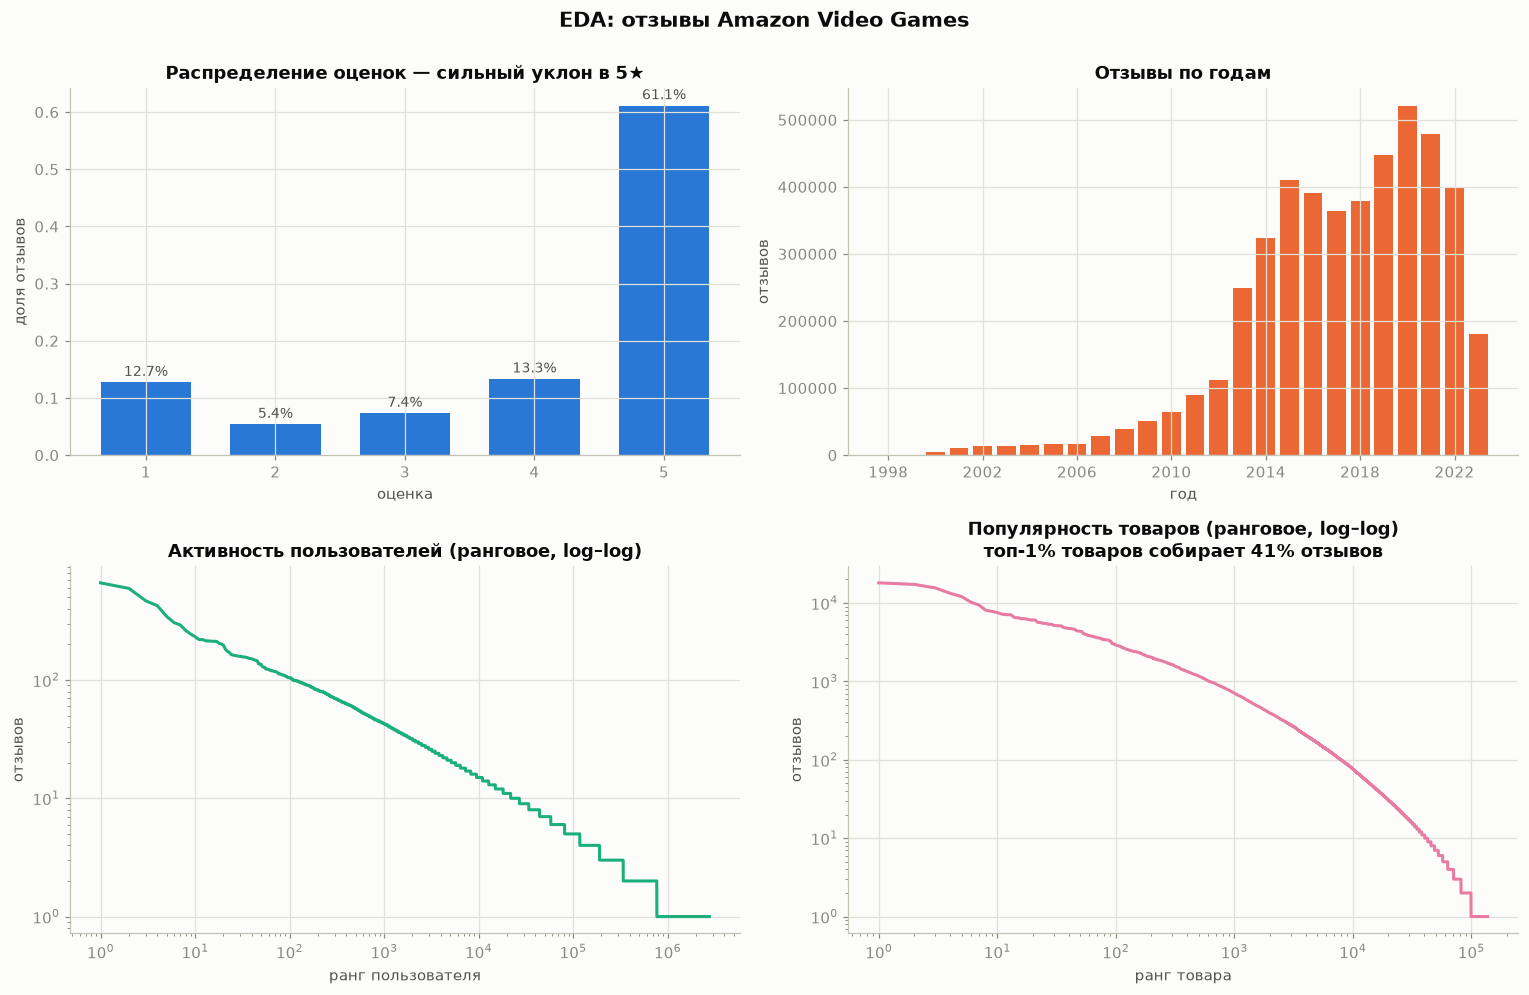

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

ax = axes[0, 0]
rd = reviews.rating.value_counts(normalize=True).sort_index()
ax.bar(rd.index.astype(str), rd.values, color=CAT[0], width=0.7)
ax.bar_label(ax.containers[0], labels=[f"{v:.1%}" for v in rd.values], padding=2, fontsize=9, color=INK2)
ax.set_title("Распределение оценок — сильный уклон в 5★")
ax.set_xlabel("оценка")
ax.set_ylabel("доля отзывов")

ax = axes[0, 1]
by_year = reviews.timestamp.dt.year.value_counts().sort_index()
ax.bar(by_year.index, by_year.values, color=CAT[1], width=0.8)
ax.set_title("Отзывы по годам")
ax.set_xlabel("год")
ax.set_ylabel("отзывов")
ax.set_xticks(range(1998, 2024, 4))

ax = axes[1, 0]
uc = reviews.user_id.value_counts().values
ax.loglog(np.arange(1, len(uc) + 1), np.sort(uc)[::-1], color=CAT[2], linewidth=2)
ax.set_title("Активность пользователей (ранговое, log–log)")
ax.set_xlabel("ранг пользователя")
ax.set_ylabel("отзывов")

ax = axes[1, 1]
ic = reviews.parent_asin.value_counts().values
ax.loglog(np.arange(1, len(ic) + 1), np.sort(ic)[::-1], color=CAT[4], linewidth=2)
share_top1 = ic[: max(1, len(ic) // 100)].sum() / ic.sum()
ax.set_title(f"Популярность товаров (ранговое, log–log)\nтоп-1% товаров собирает {share_top1:.0%} отзывов")
ax.set_xlabel("ранг товара")
ax.set_ylabel("отзывов")

fig.suptitle("EDA: отзывы Amazon Video Games", fontsize=14, fontweight="bold", color=INK, y=1.00)
fig.tight_layout()
plt.show()

### 3.2. Анализ каталога

> Сделать разведочный анализ данных (EDA), то есть описать исходные данные, а также посчитать статистические показатели, построить визуализации и дать им интерпретацию, подготовить отчёт по качеству данных (пропуски, дубли, выбросы). Четко выделить целевую переменную - “что именно рекомендуем?” При необходимости предобработать данные. Сделать выводы.


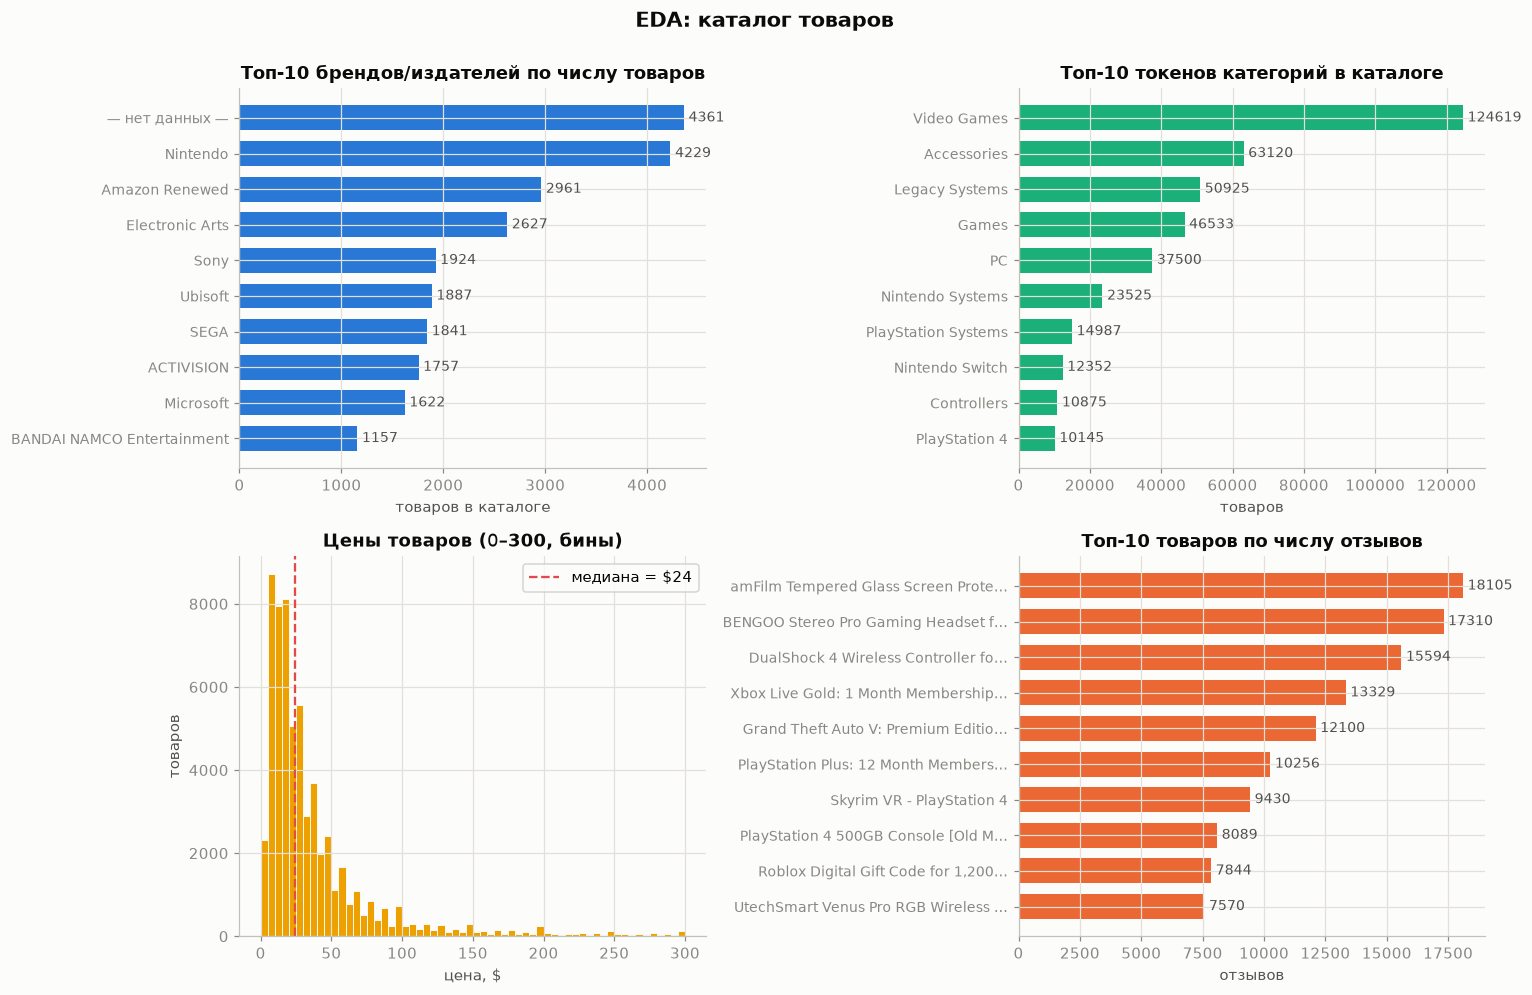

In [7]:
meta_i = meta.set_index("parent_asin")
game_titles = meta_i.title.to_dict()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

ax = axes[0, 0]
stores = meta.store.fillna("— нет данных —").value_counts().head(10)[::-1]
ax.barh(stores.index, stores.values, color=CAT[0], height=0.7)
ax.bar_label(ax.containers[0], padding=3, fontsize=9, color=INK2)
ax.set_title("Топ-10 брендов/издателей по числу товаров")
ax.set_xlabel("товаров в каталоге")
ax.tick_params(axis="y", labelsize=9)

ax = axes[0, 1]
def cat_tokens(path_list):
    out = Counter()
    for path in (path_list if isinstance(path_list, list) else []):
        out.update(t.strip() for t in str(path).split(",") if t.strip())
    return out
tok_counter = Counter()
for cl in meta.categories:
    tok_counter.update(cat_tokens(cl))
toks = pd.Series(tok_counter).sort_values(ascending=False).head(10)[::-1]
ax.barh(toks.index, toks.values, color=CAT[2], height=0.7)
ax.bar_label(ax.containers[0], padding=3, fontsize=9, color=INK2)
ax.set_title("Топ-10 токенов категорий в каталоге")
ax.set_xlabel("товаров")
ax.tick_params(axis="y", labelsize=9)

ax = axes[1, 0]
def parse_price(p):
    if isinstance(p, (int, float)) and not pd.isna(p):
        return float(p)
    if isinstance(p, str):
        m = re.search(r"(\d+(?:\.\d+)?)", p.replace(",", ""))
        return float(m.group(1)) if m else np.nan
    return np.nan
prices = meta.price.map(parse_price).dropna()
prices = prices[(prices > 0) & (prices < 300)]
ax.hist(prices, bins=60, color=CAT[3], edgecolor="#fcfcfb", linewidth=0.6)
ax.axvline(prices.median(), color=CAT[7], linestyle="--", linewidth=1.5, label=f"медиана = ${prices.median():.0f}")
ax.set_title(f"Цены товаров (${prices.min():.0f}–${prices.max():.0f}, бины)")
ax.set_xlabel("цена, $")
ax.set_ylabel("товаров")
ax.legend()

ax = axes[1, 1]
top_games = reviews.parent_asin.value_counts().head(10)[::-1]
labels = [f"{game_titles.get(a, a)[:34]}…" if len(game_titles.get(a, a)) > 34 else game_titles.get(a, a) for a in top_games.index]
ax.barh(labels, top_games.values, color=CAT[1], height=0.7)
ax.bar_label(ax.containers[0], padding=3, fontsize=9, color=INK2)
ax.set_title("Топ-10 товаров по числу отзывов")
ax.set_xlabel("отзывов")
ax.tick_params(axis="y", labelsize=9)

fig.suptitle("EDA: каталог товаров", fontsize=14, fontweight="bold", color=INK, y=1.00)
fig.tight_layout()
plt.show()

### Отчёт по качеству данных

> Сделать разведочный анализ данных (EDA), то есть описать исходные данные, а также посчитать статистические показатели, построить визуализации и дать им интерпретацию, подготовить отчёт по качеству данных (пропуски, дубли, выбросы). Четко выделить целевую переменную - “что именно рекомендуем?” При необходимости предобработать данные. Сделать выводы.

Проверяем пропуски, дубликаты, выбросы и логическую согласованность.


In [8]:
report = []

review_fields = {'rating': 'Без оценки', 'parent_asin': 'Без ID товара', 'user_id': 'Без ID пользователя', 'timestamp': 'Без даты отзыва', 'verified_purchase': 'Без признака покупки'}
for col, label in review_fields.items():
    report.append((label, int(reviews[col].isna().sum())))
meta_fields = {'title': 'Без названия товара', 'store': 'Без бренда / продавца', 'price': 'Без цены', 'categories': 'Без категории'}
for col, label in meta_fields.items():
    report.append((label, int(meta[col].isna().sum())))

report += [
    ("Одинаковые строки отзывов", int(reviews.duplicated().sum())),
    ("Повторные отзывы одного пользователя на товар", int(reviews.duplicated(subset=["user_id", "parent_asin"]).sum())),
    ("Оценка вне 1–5", int((~reviews.rating.between(1, 5)).sum())),
    ("Дата вне 1995–2024", int((~reviews.timestamp.dt.year.between(1995, 2024)).sum())),
    ("Товар без карточки", int((~reviews.parent_asin.isin(meta.parent_asin)).sum())),
]
qdf = pd.DataFrame(report, columns=["Показатель", "Количество строк"])
display(qdf)

u_counts = reviews.user_id.value_counts()
i_counts = reviews.parent_asin.value_counts()
outliers = pd.DataFrame({
    "метрика": ["Максимальное число отзывов на пользователя", "Медианное число отзывов на пользователя",
                "Максимальное число отзывов на товар", "Медианное число отзывов на товар",
                "Доля пользователей с одним отзывом", "Доля товаров с менее чем 5 отзывами"],
    "значение": [int(u_counts.max()), int(u_counts.median()), int(i_counts.max()), int(i_counts.median()),
                 f"{(u_counts == 1).mean():.1%}", f"{(i_counts < 5).mean():.1%}"],
})
display(outliers)

,Показатель,Количество строк
0,Без оценки,0
1,Без ID товара,0
2,Без ID пользователя,0
3,Без даты отзыва,0
4,Без признака покупки,0
5,Без названия товара,0
6,Без бренда / продавца,4361
7,Без цены,75261
8,Без категории,0
9,Одинаковые строки отзывов,53650


,метрика,значение
0,Максимальное число отзывов на пользователя,664
1,Медианное число отзывов на пользователя,1
2,Максимальное число отзывов на товар,18105
3,Медианное число отзывов на товар,4
4,Доля пользователей с одним отзывом,72.2%
5,Доля товаров с менее чем 5 отзывами,54.0%


**Вывод.** В ключевых полях отзывов нет пропусков; оценок и дат вне проверяемых диапазонов также не обнаружено. Для всех товаров из отзывов найдены карточки в каталоге.

Обнаружены 53 650 дубликатов по загруженным полям и 69 115 повторных пар пользователь–товар. Полные дубликаты входят в повторные пары, поэтому эти числа не складываются. При предобработке оставляем последний по времени отзыв для каждой пары — это устраняет оба вида повторов.

В каталоге отсутствуют 4 361 значение бренда / продавца и 75 261 значение цены. На графике брендов пропуски объединяем в группу «нет данных»; товары без цены исключаем только из анализа цен. Для обучения рекомендаций эти товары сохраняем: MostPop, ItemKNN и EASE не используют бренд и цену.

Большинство пользователей имеют короткую историю, а популярность товаров распределена неравномерно.


## 4. Предобработка и разделение выборок

> Сделать разведочный анализ данных (EDA), то есть описать исходные данные, а также посчитать статистические показатели, построить визуализации и дать им интерпретацию, подготовить отчёт по качеству данных (пропуски, дубли, выбросы). Четко выделить целевую переменную - “что именно рекомендуем?” При необходимости предобработать данные. Сделать выводы.

> Выделить обучающую и тестовую выборки. На тестовой выборки вычислить значения выбранных метрик качества. Сравнить методы и дать интерпретацию результатов по полученным метрикам.

Удаляем строки без ключевых полей, некорректные оценки и товары без метаданных. Для каждой пары пользователь–товар оставляем последний отзыв. Итеративно оставляем пользователей с ≥5 и товары с ≥20 взаимодействиями, затем случайно выбираем 50 000 пользователей.

Последние 20% взаимодействий каждого пользователя (с округлением вверх) выделяем в тест. Товары, отсутствующие в train, исключаем из оценки. Все оставшиеся отзывы кодируем единицей.


In [9]:
def kcore(df, min_user=5, min_item=20):
    while True:
        n0 = len(df)
        df = df[df.parent_asin.isin(df.parent_asin.value_counts().loc[lambda s: s >= min_item].index)]
        df = df[df.user_id.isin(df.user_id.value_counts().loc[lambda s: s >= min_user].index)]
        if len(df) == n0:
            return df

steps = [("исходные отзывы", reviews)]
d = reviews.dropna(subset=["user_id", "parent_asin", "timestamp", "rating"])
d = d[d.rating.between(1, 5) & d.parent_asin.isin(meta.parent_asin)]
d = d.sort_values("timestamp").drop_duplicates(subset=["user_id", "parent_asin"], keep="last")
steps.append(("после дедупликации user–item", d))
d = kcore(d, min_user=5, min_item=20)
steps.append(("k-core (юзер ≥ 5, товар ≥ 20)", d))
users_all = d.user_id.unique()
d = d[d.user_id.isin(set(pd.Series(users_all).sample(50_000, random_state=RANDOM_STATE)))]
steps.append(("подвыборка 50 000 пользователей", d))

hist = pd.DataFrame([
    (name, f"{len(df):,}", f"{df.user_id.nunique():,}", f"{df.parent_asin.nunique():,}")
    for name, df in steps
], columns=["шаг", "взаимодействий", "пользователей", "товаров"])
display(hist)
d = d.sort_values(["user_id", "timestamp"]).reset_index(drop=True)

,шаг,взаимодействий,пользователей,товаров
0,исходные отзывы,"4,624,615","2,766,656","137,249"
1,после дедупликации user–item,"4,555,500","2,766,656","137,249"
2,"k-core (юзер ≥ 5, товар ≥ 20)","502,571","59,964","6,329"
3,подвыборка 50 000 пользователей,"418,160","50,000","6,329"


### 4.1. Обучающая и тестовая выборки

> Выделить обучающую и тестовую выборки. На тестовой выборки вычислить значения выбранных метрик качества. Сравнить методы и дать интерпретацию результатов по полученным метрикам.


In [10]:
grp = d.groupby("user_id")
n_all = grp.cumcount() + 1
n_tot = grp["user_id"].transform("size")
test_mask = n_all > np.floor(n_tot * 0.8).astype(int)

train_df, test_df = d[~test_mask].copy(), d[test_mask].copy()

train_items = set(train_df.parent_asin)
cold = ~test_df.parent_asin.isin(train_items)
test_df = test_df[~cold]

u_sizes = train_df.groupby("user_id").size()
t_sizes = test_df.groupby("user_id").size()
display(pd.Series({
    "train: взаимодействий": f"{len(train_df):,}",
    "test: взаимодействий": f"{len(test_df):,}",
    "пользователей в test": f"{test_df.user_id.nunique():,}",
    "train на пользователя (мин / медиана / макс)": f"{u_sizes.min()} / {int(u_sizes.median())} / {u_sizes.max()}",
    "test на пользователя (в среднем)": round(t_sizes.mean(), 2),
    "разреженность train": f"{1 - len(train_df) / (u_sizes.size * len(train_items)):.4%}",
}).to_frame("значение"))

,значение
train: взаимодействий,"316,762"
test: взаимодействий,"101,339"
пользователей в test,"49,985"
train на пользователя (мин / медиана / макс),4 / 4 / 258
test на пользователя (в среднем),2.03
разреженность train,99.8999%


**Вывод.** В train — 316 762 взаимодействия, в test — 101 339. В тесте оставлены только товары, встречающиеся в обучающей выборке. Разреженность train — 99,90%.


## 5. Методы рекомендаций

> Выбрать минимум три метода формирования рекомендации. Реализовать их. Рекомендуемые методы: 1) MostPop, 2) UserKNN или ItemKNN, 3) SLIM или EASE, 4) версии SVD или ALS. При выборе методов старайтесь брать методы из разных семейств.

Реализуем три метода из разных семейств:

| # | Метод | Семейство | персональность |
|---|---|---|---|
| 1 | MostPop | неперсональный | нет |
| 2 | ItemKNN | соседство | да |
| 3 | EASE | линейная авто-модель | да |

Единый протокол: метод обучается на train-матрице, для каждого пользователя возвращает топ-$N=20$ товаров. Метрика отчёта — $K=10$.

Гиперпараметры (число соседей ItemKNN, $\lambda$ EASE) подбираем на валидационной выборке: последний отзыв каждого пользователя, выделенный из train

In [11]:
users = sorted(train_df.user_id.unique())
items = sorted(train_items)
u2i = {u: k for k, u in enumerate(users)}
i2i = {a: k for k, a in enumerate(items)}
n_users, n_items = len(users), len(items)
print(f"матрица: {n_users} пользователей x {n_items} товаров")

def to_csr(df):
    u = df.user_id.map(u2i).astype(int)
    i = df.parent_asin.map(i2i).astype(int)
    return sp.csr_matrix((np.ones(len(df), dtype=np.float32), (u, i)), shape=(n_users, n_items))

X_train = to_csr(train_df).tocsr()

def to_sets(df):
    sets = [set() for _ in range(n_users)]
    for u, i in zip(df.user_id.map(u2i), df.parent_asin.map(i2i)):
        sets[int(u)].add(int(i))
    return sets

test_sets = to_sets(test_df)
eval_users = np.array([u for u in range(n_users) if test_sets[u]])
print(f"пользователей с непустым тестом: {len(eval_users):,}")

train_sorted = train_df.sort_values(["user_id", "timestamp"])
val_mask = train_sorted.groupby("user_id").cumcount(ascending=False) == 0
val_df = train_sorted[val_mask]
fit_df = train_sorted[~val_mask]
fit_items = set(fit_df.parent_asin)
val_df = val_df[val_df.parent_asin.isin(fit_items)]
X_fit, val_sets = to_csr(fit_df).tocsr(), to_sets(val_df)
val_users = np.array([u for u in range(n_users) if val_sets[u]])

def topn_from_scores(score_fn, X=X_train, n=n_users, N=TOP_N, chunk=5000):
    out = np.zeros((n, N), dtype=np.int32)
    for s in range(0, n, chunk):
        e = min(s + chunk, n)
        rows = np.arange(s, e)
        Sc = score_fn(rows)
        Sc[X[rows].toarray() > 0] = -np.inf
        Sc[:, np.asarray(X.sum(axis=0)).ravel() == 0] = -np.inf
        candidates = np.argpartition(-Sc, N - 1, axis=1)[:, :N]
        scores = np.take_along_axis(Sc, candidates, axis=1)
        order = np.argsort(-scores, axis=1, kind="stable")
        out[s:e] = np.take_along_axis(candidates, order, axis=1)
    return out

def recall_at_k(top, ground, users_idx, K):
    vals = [len(set(top[u, :K].tolist()) & ground[u]) / len(ground[u]) for u in users_idx]
    return float(np.mean(vals))

def show_titles(item_ids, k=5):
    return [game_titles.get(items[j], items[j])[:38] for j in item_ids[:k]]

demo_cand = [u for u in range(n_users) if 8 <= X_train[u].nnz <= 14]
demo_u = int(demo_cand[rng.integers(len(demo_cand))])
print(f"демонстрационный пользователь #{demo_u}, история: {show_titles(X_train[demo_u].indices, 12)}")

матрица: 50000 пользователей x 6326 товаров
пользователей с непустым тестом: 49,985
демонстрационный пользователь #4606, история: ['StarCraft II: Heart of the Swarm Expan', 'PlayStation Plus: 12 Month Membership ', 'Sony PS3 Media/Blu-ray Disc Remote Con', "Injustice: Gods Among Us - Collector's", 'inFAMOUS: Second Son Standard Edition ', 'Tomb Raider: Definitive Edition - Xbox', "Assassin's Creed Unity Limited Edition", 'PlayStation 4 Console - Destiny Bundle', 'Game of Thrones - A Telltale Games Ser', 'Knack (PlayStation 4)', 'ABZÛ - Xbox One']


### 5.1. MostPop

> Выбрать минимум три метода формирования рекомендации. Реализовать их. Рекомендуемые методы: 1) MostPop, 2) UserKNN или ItemKNN, 3) SLIM или EASE, 4) версии SVD или ALS. При выборе методов старайтесь брать методы из разных семейств.

MostPop ранжирует товары по числу взаимодействий в train и исключает уже просмотренные.


In [12]:
class MostPop:
    def fit(self, X):
        self.pop_ = np.asarray(X.sum(axis=0)).ravel().astype(np.float32)
        return self
    def scores(self, rows, X=None):
        return np.tile(self.pop_, (len(rows), 1))
    def recommend(self, X, N=TOP_N):
        return topn_from_scores(self.scores, X=X, n=X.shape[0], N=N)

models = {}
rec_pop = topn_from_scores(MostPop().fit(X_train).scores)
print("MostPop, пример для demo-пользователя:", show_titles(rec_pop[demo_u]))

MostPop, пример для demo-пользователя: ['Grand Theft Auto V: Premium Edition - ', 'Skyrim VR - PlayStation 4', 'amFilm Tempered Glass Screen Protector', 'PlayStation 4 500GB Console [Old Model', 'Xbox Live Gold: 1 Month Membership [Di']


### 5.2. ItemKNN

> Выбрать минимум три метода формирования рекомендации. Реализовать их. Рекомендуемые методы: 1) MostPop, 2) UserKNN или ItemKNN, 3) SLIM или EASE, 4) версии SVD или ALS. При выборе методов старайтесь брать методы из разных семейств.

Вычисляем косинусную близость столбцов матрицы взаимодействий и оставляем ближайших соседей каждого товара без самого товара


In [13]:
def knn_similarity(X, k_max):
    Xi = X.T.tocsr()
    nn = NearestNeighbors(n_neighbors=k_max + 1, metric="cosine", algorithm="brute", n_jobs=-1).fit(Xi)
    dist, idx = nn.kneighbors(Xi)
    return idx, 1.0 - dist

def knn_matrix(k, idx, sim):
    S = sp.csr_matrix((sim[:, :k + 1].ravel(),
                          (np.repeat(np.arange(n_items), k + 1), idx[:, :k + 1].ravel())),
                         shape=(n_items, n_items))
    S.setdiag(0)
    S.eliminate_zeros()
    return S

nbr_idx, nbr_sim = knn_similarity(X_fit, k_max=500)

print("подбор K (число соседей) по Recall@10 на валидации:")
knn_val = {}
for K in [50, 100, 200, 500]:
    S = knn_matrix(K, nbr_idx, nbr_sim)
    top = topn_from_scores(lambda rows: (X_fit[rows] @ S).toarray().astype(np.float32), X=X_fit)
    knn_val[K] = recall_at_k(top, val_sets, val_users, K_MAIN)
    print(f"  K = {K:>4}: Recall@10 = {knn_val[K]:.4f}")
best_knn_k = max(knn_val, key=knn_val.get)
print(f"выбрано K = {best_knn_k}")

idx_tr, sim_tr = knn_similarity(X_train, k_max=best_knn_k)
S_final = knn_matrix(best_knn_k, idx_tr, sim_tr)
models["ItemKNN"] = lambda rows: (X_train[rows] @ S_final).toarray().astype(np.float32)
rec_knn = topn_from_scores(models["ItemKNN"])
print("ItemKNN, пример:", show_titles(rec_knn[demo_u]))

подбор K (число соседей) по Recall@10 на валидации:
  K =   50: Recall@10 = 0.0990
  K =  100: Recall@10 = 0.1012
  K =  200: Recall@10 = 0.1035
  K =  500: Recall@10 = 0.1058
выбрано K = 500
ItemKNN, пример: ['Killzone: Shadow Fall (PlayStation 4)', 'PlayStation 4 500GB Console [Old Model', "Assassin's Creed IV Black Flag - PC", 'The Order: 1886 - PlayStation 4', 'DualShock 4 Wireless Controller for Pl']


### 5.3. EASE

> Выбрать минимум три метода формирования рекомендации. Реализовать их. Рекомендуемые методы: 1) MostPop, 2) UserKNN или ItemKNN, 3) SLIM или EASE, 4) версии SVD или ALS. При выборе методов старайтесь брать методы из разных семейств.

EASE решает $\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2$ при $B_{ii}=0$.

In [14]:
def ease_fit(X, lam):
    G = (X.T @ X).toarray().astype(np.float64)
    P = np.linalg.inv(G + lam * np.eye(X.shape[1]))
    B = -P / np.diag(P)[None, :]
    np.fill_diagonal(B, 0.0)
    return B.astype(np.float32)

print("подбор lambda по Recall@10 на валидации:")
ease_val = {}
for lam in [150.0, 300.0, 700.0, 1500.0, 3000.0]:
    B = ease_fit(X_fit, lam)
    top = topn_from_scores(lambda rows: np.asarray(X_fit[rows] @ B), X=X_fit)
    ease_val[lam] = recall_at_k(top, val_sets, val_users, K_MAIN)
    print(f"  lambda = {lam:>6.0f}: Recall@10 = {ease_val[lam]:.4f}")
best_ease_lam = max(ease_val, key=ease_val.get)
print(f"выбрана lambda = {best_ease_lam:.0f}")

B_ease = ease_fit(X_train, best_ease_lam)
models["EASE"] = lambda rows: np.asarray(X_train[rows] @ B_ease)
rec_ease = topn_from_scores(models["EASE"])
print("EASE, пример:", show_titles(rec_ease[demo_u]))

подбор lambda по Recall@10 на валидации:
  lambda =    150: Recall@10 = 0.1271
  lambda =    300: Recall@10 = 0.1255
  lambda =    700: Recall@10 = 0.1227
  lambda =   1500: Recall@10 = 0.1201
  lambda =   3000: Recall@10 = 0.1178
выбрана lambda = 150
EASE, пример: ['Killzone: Shadow Fall (PlayStation 4)', 'PlayStation 4 500GB Console [Old Model', "Assassin's Creed IV Black Flag - PC", 'Far Cry 4 - PS3 [Digital Code]', 'DualShock 4 Wireless Controller for Pl']


## 6. Метрики качества

> Выбрать не менее четырех метрик оценки качества рекомендаций. Рассчитать их. Нужно выбрать хотя бы одну метрику, учитывающую качество ранжирования. Нужно выбрать хотя бы одну специфическую для рекомендательных систем метрику (новизна, разнообразие, serendipity/неожиданность).

Считаем семь метрик по первым 10 рекомендациям. Релевантными считаем товары из тестовой истории пользователя.

**Качество попаданий и порядка:**

1. **Recall@10** — какую долю тестовых товаров нашли среди первых 10 рекомендаций.
2. **NDCG@10** — насколько высоко стоят найденные тестовые товары; попадание в начало списка ценнее попадания в конец.
3. **MAP@10** — насколько точно список выдаёт релевантные товары к моменту каждого попадания. Показатель выше, если перед релевантными товарами меньше нерелевантных рекомендаций.

**Охват и свойства рекомендаций:**

4. **Coverage@10** — какую долю каталога рекомендовали хотя бы одному оцениваемому пользователю.
5. **Novelty@10** — насколько непопулярные товары рекомендует модель. Популярность считаем только по обучающим взаимодействиям; результат выражен в битах.
6. **Diversity (ILD)@10** — насколько различаются категории товаров внутри одного списка, в среднем по пользователям.
7. **Serendipity@10** — насколько рекомендации одновременно полезны и неожиданны. Учитываем только попадания в тест и их отличие от категорий обучающей истории. Сумму вкладов делим на длину списка и усредняем по пользователям; без попаданий значение равно нулю.


In [ ]:
def ranking_metrics(top, ground, users_idx, K):
    rec, ndcg, ap = [], [], []
    disc = 1.0 / np.log2(np.arange(2, K + 2))
    for u in users_idx:
        T = ground[u]
        hits = np.isin(top[u, :K], list(T)).astype(float)
        rec.append(hits.sum() / len(T))
        dcg = (hits * disc).sum()
        idcg = disc[: min(len(T), K)].sum()
        ndcg.append(dcg / idcg if idcg > 0 else 0.0)
        prec = np.cumsum(hits) / np.arange(1, K + 1)
        ap.append((hits * prec).sum() / min(len(T), K))
    return float(np.mean(rec)), float(np.mean(ndcg)), float(np.mean(ap))

def cat_matrix():
    rows_, cols_, vocab = [], [], {}
    for j, asin in enumerate(items):
        for t in cat_tokens(meta_i.categories.get(asin)):
            if t not in vocab:
                vocab[t] = len(vocab)
            rows_.append(j); cols_.append(vocab[t])
    C = sp.csr_matrix((np.ones(len(rows_)), (rows_, cols_)), shape=(n_items, len(vocab)), dtype=np.float64)
    df = np.asarray((C > 0).sum(axis=0)).ravel() / n_items
    keep = np.where(df <= 0.7)[0]
    C = C[:, keep]
    C = sp.diags(1.0 / np.sqrt(np.asarray(C.multiply(C).sum(axis=1)).ravel().clip(1e-12))) @ C
    return C.tocsr()

C_cat = cat_matrix()
cat_pop = np.asarray(X_train.sum(axis=0)).ravel()
cat_p = cat_pop / cat_pop.sum()

def beyond_metrics(top, Cmat, p, X, K):
    lists = top[eval_users, :K]
    cov = len(np.unique(lists.ravel())) / n_items
    nov = float((-np.log2(p[lists.ravel()])).mean())
    Cd = Cmat.toarray()
    Csum = np.zeros((len(lists), Cd.shape[1]))
    for k in range(K):
        Csum += Cd[lists[:, k]]
    sq = (Csum ** 2).sum(axis=1)
    ild = float((1 - (sq - (Cd[lists] ** 2).sum(axis=(1, 2))) / (K * (K - 1))).mean())
    hist = np.asarray(X @ Cd)
    hist /= np.linalg.norm(hist, axis=1, keepdims=True).clip(1e-12)
    ser = []
    for row, u in enumerate(eval_users):
        value = 0.0
        T = test_sets[u]
        for j in lists[row]:
            if j in T:
                value += 1 - Cd[j] @ hist[u]
        ser.append(value / K)
    ser = float(np.mean(ser))
    return {"Coverage": cov, "Novelty": nov, "ILD": ild, "Serendipity": ser}

## 7. Сравнение методов

> Выделить обучающую и тестовую выборки. На тестовой выборки вычислить значения выбранных метрик качества. Сравнить методы и дать интерпретацию результатов по полученным метрикам.

Для трёх моделей формируем списки из 20 товаров. По первым 10 рекомендациям сравниваем все семь выбранных метрик: Recall, NDCG, MAP, Coverage, Novelty, ILD и Serendipity. Дополнительно строим кривые Recall и NDCG при длине списка 1, 5, 10 и 20.

In [16]:
recs = {"MostPop": rec_pop, "ItemKNN": rec_knn, "EASE": rec_ease}
t0 = time.time()
rows = []
for name, top in recs.items():
    r, n, m = ranking_metrics(top, test_sets, eval_users, K_MAIN)
    b = beyond_metrics(top, C_cat, cat_p, X_train, K_MAIN)
    rows.append({"метод": name, "Recall@10": r, "NDCG@10": n, "MAP@10": m, **b})
results = pd.DataFrame(rows).set_index("метод").loc[MODELS]
display(results.round(4))
print(f"расчёт метрик: {time.time()-t0:.0f} с")

,Recall@10,NDCG@10,MAP@10,Coverage,Novelty,ILD,Serendipity
метод,,,,,,,
MostPop,0.0334,0.0198,0.0116,0.0028,8.2719,0.8415,0.0045
ItemKNN,0.0878,0.0563,0.0377,0.9930,11.8496,0.5112,0.0058
EASE,0.1047,0.0677,0.0454,0.7072,10.4676,0.5966,0.0078


расчёт метрик: 3 с


### 7.1. Сравнение метрик

> Выделить обучающую и тестовую выборки. На тестовой выборки вычислить значения выбранных метрик качества. Сравнить методы и дать интерпретацию результатов по полученным метрикам.


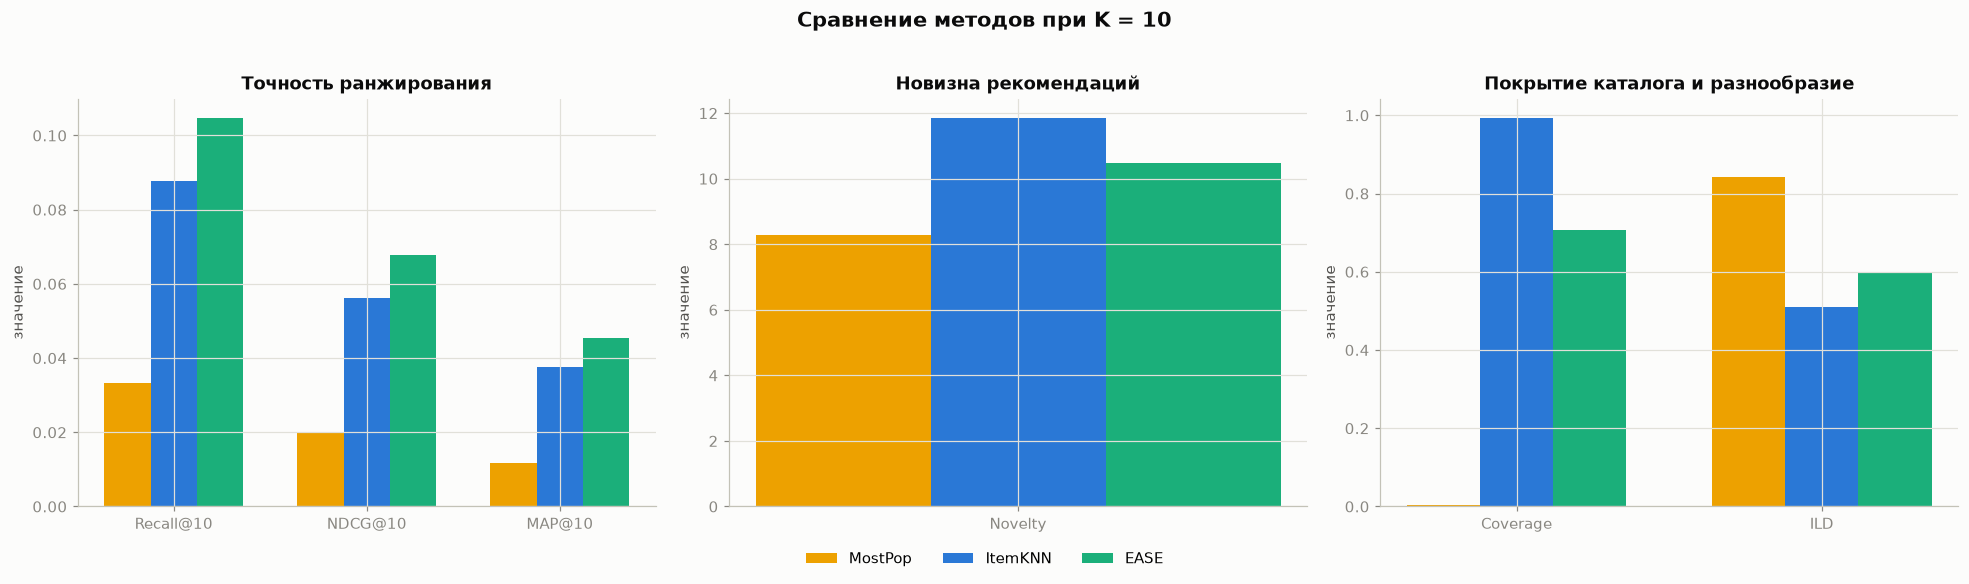

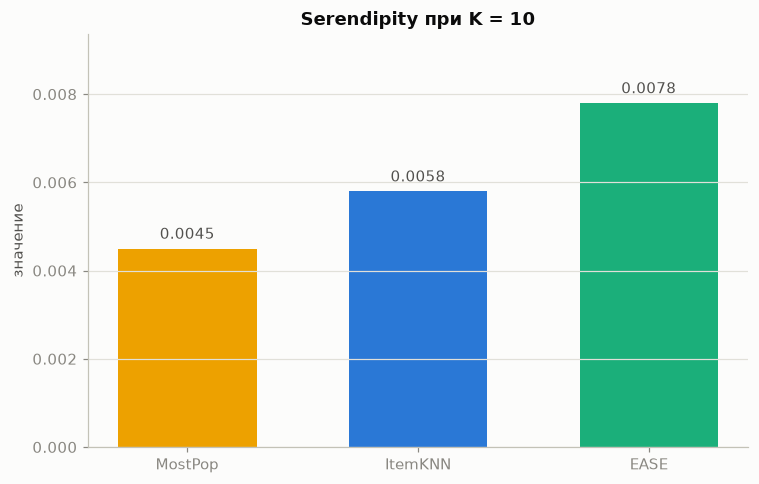

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

w = 0.24
def grouped(ax, data, title, ylabel="значение"):
    x = np.arange(len(data.columns))
    for k, name in enumerate(MODELS):
        ax.bar(x + (k - (len(MODELS) - 1) / 2) * w, data.loc[name], w, label=name, color=MODEL_COLOR[name])
    ax.set_xticks(x); ax.set_xticklabels(data.columns)
    ax.set_title(title); ax.set_ylabel(ylabel)

grouped(axes[0], results[["Recall@10", "NDCG@10", "MAP@10"]], "Точность ранжирования")
grouped(axes[1], results[["Novelty"]], "Новизна рекомендаций")
grouped(axes[2], results[["Coverage", "ILD"]], "Покрытие каталога и разнообразие")

handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncols=len(MODELS), frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Сравнение методов при K = 10", fontsize=14, fontweight="bold", color=INK, y=1.02)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(MODELS, results.loc[MODELS, "Serendipity"],
              color=[MODEL_COLOR[name] for name in MODELS], width=0.6)
ax.bar_label(bars, fmt="%.4f", padding=4, color=INK2)
ax.set_title("Serendipity при K = 10")
ax.set_ylabel("значение")
ax.set_ylim(0, results["Serendipity"].max() * 1.2)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()


### 7.2. Качество при разной длине списка

> Выделить обучающую и тестовую выборки. На тестовой выборки вычислить значения выбранных метрик качества. Сравнить методы и дать интерпретацию результатов по полученным метрикам.


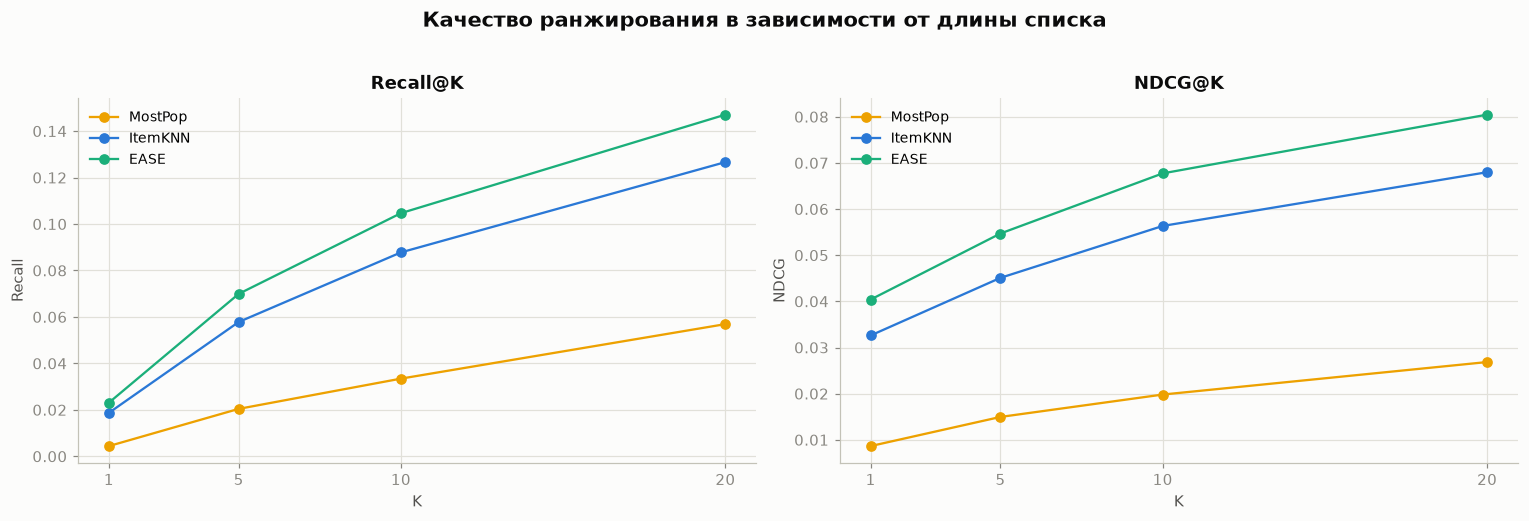

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ks = [1, 5, 10, 20]
for name in MODELS:
    r_k = [recall_at_k(recs[name], test_sets, eval_users, k) for k in ks]
    axes[0].plot(ks, r_k, marker="o", label=name, color=MODEL_COLOR[name])
axes[0].set_title("Recall@K")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Recall")
axes[0].set_xticks(ks); axes[0].legend(frameon=False, fontsize=9)

for name in MODELS:
    nd_k = [ranking_metrics(recs[name], test_sets, eval_users, k)[1] for k in ks]
    axes[1].plot(ks, nd_k, marker="o", label=name, color=MODEL_COLOR[name])
axes[1].set_title("NDCG@K")
axes[1].set_xlabel("K"); axes[1].set_ylabel("NDCG")
axes[1].set_xticks(ks); axes[1].legend(frameon=False, fontsize=9)

fig.suptitle("Качество ранжирования в зависимости от длины списка", fontsize=14,
             fontweight="bold", color=INK, y=1.02)
fig.tight_layout()
plt.show()

### 7.3. Пример рекомендаций

> Выделить обучающую и тестовую выборки. На тестовой выборки вычислить значения выбранных метрик качества. Сравнить методы и дать интерпретацию результатов по полученным метрикам.


In [19]:
hist_titles = show_titles(X_train[demo_u].indices, 10)
demo_rows = [("история (train)", " | ".join(hist_titles[:5]))]
for name in MODELS:
    demo_rows.append((name, " | ".join(show_titles(recs[name][demo_u], 5))))
display(pd.DataFrame(demo_rows, columns=["источник", "товары (первые 5)"]))

,источник,товары (первые 5)
0,история (train),StarCraft II: Heart of the Swarm Expan | PlayStation Plus: 12 Month Membership | Sony...
1,MostPop,Grand Theft Auto V: Premium Edition - | Skyrim VR - PlayStation 4 | amFilm Tempered G...
2,ItemKNN,Killzone: Shadow Fall (PlayStation 4) | PlayStation 4 500GB Console [Old Model | Assas...
3,EASE,Killzone: Shadow Fall (PlayStation 4) | PlayStation 4 500GB Console [Old Model | Assas...


**Сравнение по всем выбранным метрикам.**

- **Recall@10:** EASE — 0,1047, ItemKNN — 0,0878, MostPop — 0,0334. EASE находит в среднем 10,47% тестовых товаров пользователя и превосходит MostPop примерно в 3,1 раза.
- **NDCG@10:** EASE — 0,0677, ItemKNN — 0,0563, MostPop — 0,0198. EASE лучше с учётом позиций релевантных товаров в списке.
- **MAP@10:** EASE — 0,0454, ItemKNN — 0,0377, MostPop — 0,0116. EASE также лидирует по точности на позициях попаданий: найденные тестовые товары меньше оттесняются нерелевантными рекомендациями.
- **Coverage@10:** ItemKNN — 99,30%, EASE — 70,72%, MostPop — 0,28%. ItemKNN рекомендует почти весь каталог в совокупности по пользователям; MostPop концентрируется на узком наборе популярных товаров.
- **Novelty@10:** ItemKNN — 11,8496 бита, EASE — 10,4676, MostPop — 8,2719. ItemKNN чаще предлагает менее популярные товары. Это дополняет его высокий охват, но само по себе не гарантирует полезность рекомендаций.
- **ILD@10:** MostPop - 0,8415, EASE — 0,5966, ItemKNN — 0,5112. У MostPop категории внутри списка наиболее различаются, хотя его рекомендации менее точны. Разнообразие одного списка и охват всего каталога — разные свойства: у ItemKNN максимальный охват, но минимальный ILD.
- **Serendipity@10:** EASE — 0,0078, ItemKNN — 0,0058, MostPop — 0,0045. В выбранном определении EASE лучше сочетает попадание в тест с отличием от привычных категорий пользователя. Это оценка по взаимодействиям и категориям, а не измерение реального удивления человека.

**Вывод.** EASE лидирует по трём метрикам качества попаданий и ранжирования, а также по Serendipity. ItemKNN даёт наибольшие охват и новизну; MostPop — наибольшее разнообразие категорий внутри списка. По результатам эксперимента EASE выбираем основным методом по точности, а ItemKNN рассматриваем как вариант для более широкого охвата каталога.


## 8. Предложения по улучшению и выводы

> Сформулировать предложения по улучшению качества рекомендаций. Сделать выводы.

1. Использовать общий календарный порог разделения и фильтрацию по train; отдельно оценить холодный старт.
2. Добавить категории и текстовые признаки для новых товаров, проверить гибрид коллаборативных моделей.
3. Проверить переранжирование для увеличения разнообразия и измерить изменение Recall.
4. Расширить подбор параметров ItemKNN и EASE, оценить устойчивость на нескольких разделениях.

**Итог.** На данных Amazon Reviews 2023 (Video Games) проведены разведочный анализ и проверка качества данных. Удалены повторные взаимодействия, выполнена фильтрация пользователей и товаров. Целевая переменная - факт будущего отзыва о ранее не встречавшемся пользователю товаре.

Сравнены три метода по семи метрикам. Лучшее качество ранжирования показал EASE: Recall@10 = 0,1047, NDCG@10 = 0,0677. По Recall@10 он превосходит MostPop (0,0334) примерно в 3,1 раза и ItemKNN (0,0878) примерно на 19%.

Метрики охвата и разнообразия дополняют сравнение точности. ItemKNN охватывает 99,3% каталога, EASE — 70,7%, а MostPop — только 0,28%. При этом у MostPop выше разнообразие категорий внутри списка, но ниже точность: разнообразный список сам по себе не гарантирует попадания в интересы пользователя.
